In [1]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

nlp = spacy.load('en_core_web_sm')
print('spaCy', spacy.__version__)

spaCy 3.8.16


In [2]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()
X = vec.fit_transform(docs)
tab = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                   index=['d1', 'd2', 'd3']).round(3)
print(tab)

# d1 by hand
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

# cosine d2 vs d3 (rows already length 1, so dot product)
full = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(), index=['d1','d2','d3'])
print('cosine(d2, d3) =', round(float(full.loc['d2'] @ full.loc['d3']), 3))

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}
cosine(d2, d3) = 0.544


## Part 1 Write-up: TF-IDF by Hand

### 1. IDF arithmetic
scikit-learn uses smooth IDF: **idf = ln[(1 + N) / (1 + df)] + 1**, with N = 3 documents.

| Word | df | Calculation | IDF |
|---|---|---|---|
| win | 1 | ln(4/2) + 1 | 1.693 |
| cash | 1 | ln(4/2) + 1 | 1.693 |
| me | 1 | ln(4/2) + 1 | 1.693 |
| **free** | **2** | **ln(4/3) + 1 = 0.288 + 1** | **1.288** |
| call | 2 | ln(4/3) + 1 | 1.288 |
| **now** | **3** | **ln(4/4) + 1 = 0 + 1** | **1.000** |

### 2. Hand calculation of d1 matches the library
For d1 = "win free cash now", every tf = 1, so the raw vector is
(1.693, 1.288, 1.693, 1.000). Its length is
√(1.693² + 1.288² + 1.693² + 1.000²) = √8.391 = 2.897.
Dividing each entry by 2.897 gives:

**win 0.584, free 0.445, cash 0.584, now 0.345**

This is identical to the TfidfVectorizer output, so the library does exactly
what the formula says: smooth IDF followed by L2 normalization.

### 3. Why does "now" get the lowest weight?
"now" appears in all three documents (df = N), so the ratio inside the log is 1,
ln(1) = 0, and only the +1 smoothing term remains. This is the minimum possible
IDF. Intuitively, a word that is in every message cannot help separate one message
from another, so it carries no discriminating information. The opposite case is
visible in d2: "me" occurs in only one document (idf = 1.693), so it receives the
largest weight there (0.720), even though it is not a "spam word". TF-IDF measures
rarity, not meaning, and the classifier must learn the meaning later from labels.

### 4. Cosine similarity between d2 and d3
Each row is already L2-normalized (length 1), so cosine similarity is simply the
dot product. Only "call" and "now" are non-zero in both documents:

cos(d2, d3) = (0.548 × 0.620) + (0.425 × 0.481) = 0.340 + 0.204 = **0.544**

This matches the 0.54 on slide 10 and my code output (0.544). The score is
moderate because the messages share two of their three words, but differ on
"me" versus "free". Note that "now" contributes less than "call" because its
IDF is lower, so sharing a very common word counts for less than sharing a
rarer one.

### 5. Takeaway
Reproducing the numbers by hand confirmed that every TF-IDF value is explainable:
**rarity (IDF) x frequency (TF), then scaled to unit length**. This will help
later when I read classifier weights in Part 2, because I know that a large
weight can come from a rare word and not necessarily a meaningful one.

In [5]:
import os
print(os.listdir('/kaggle/input'))

['datasets']


In [8]:
print(os.listdir('/kaggle/input/datasets/uciml'))

['sms-spam-collection-dataset']


In [9]:
import glob
print(glob.glob('/kaggle/input/datasets/*/*'))
print(glob.glob('/kaggle/input/datasets/*/*/*'))

['/kaggle/input/datasets/sheikhhaseeb123/bosssss', '/kaggle/input/datasets/uciml/sms-spam-collection-dataset', '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria']
['/kaggle/input/datasets/sheikhhaseeb123/bosssss/__results___files', '/kaggle/input/datasets/sheikhhaseeb123/bosssss/week6_model.pt', '/kaggle/input/datasets/sheikhhaseeb123/bosssss/week7-text-multimodal-ai_guided.ipynb', '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv', '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images']


In [10]:
path = '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv'
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



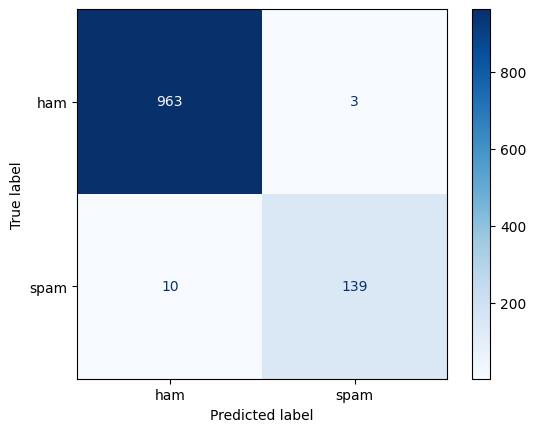

In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

In [13]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


In [14]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

## Write it (Part 2)

**Dataset:** 5,572 SMS (4,825 ham, 747 spam). Spam share is 0.134, so an "always ham" model gets 86.6% accuracy while catching no spam. I therefore report macro-F1 and spam precision/recall instead of accuracy alone.

### 1. Word vs character n-grams
| Model | Features | macro-F1 | Spam precision | Spam recall | Errors (of 1,115) |
|---|---|---|---|---|---|
| Word 1-2 grams | 12,128 | 0.974 | 0.979 | 0.933 | 13 (FP 3, FN 10) |
| Char 2-5 grams | 36,449 | 0.982 | 0.986 | 0.953 | 9 (FP 2, FN 7) |

Confusion matrices (test set): word TN = 963, FP = 3, FN = 10, TP = 139; char TN = 964, FP = 2, FN = 7, TP = 142.

Comment: The character model has about 3x more features (36,449 vs 12,128) and improves macro-F1 by 0.008 (0.974 to 0.982). It misses 3 fewer spam messages (7 vs 10) and blocks 1 fewer real message (2 vs 3). The gain is small, and on a test set of only 149 spam messages a difference of 3 messages is not strong evidence, but it points in the same direction for both precision and recall. The extra 24,000 character features cost little here (training still takes seconds), but a gain of only 3 spam messages out of 149 is too small to call the char model clearly better without repeating the split with several seeds or cross-validation.

### 2. Top features (word model)
Spam-like: call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your
Ham-like: my, me, ok, that, it, but, ll, gt, lt, can, what, da

Sensible spam signals: call, txt, text, reply, stop, claim, free, mobile, www (calls to action and offers).
Shortcuts: "uk" (the dataset is from UK SMS), "gt"/"lt" (HTML codes for > and < that appear only in ham), "ll" (tokenization leftover of I'll), "da" (informal chat word). Shortcuts such as "uk", "gt" and "lt" reflect how this dataset was collected (UK messages, HTML-escaped text), not what spam means, so the score may drop on messages from another country or platform, such as Pakistani SMS.

### 3. Error analysis (word model, 13 errors out of 1,115)

**False negatives (spam predicted as ham): 10**
| Message (shortened) | p_spam | Type | Reason |
|---|---|---|---|
| "Do you realize that in about 40 years... old ladies with tattoos?" | 0.088 | label error | Reads like a normal joke, no spam features |
| "Hi ya babe x u 4goten bout me?' scammers getting smart... Beware!" | 0.144 | ambiguous | Warns about a scam but contains spam phrases (prem rate, subscription) |
| "ringtoneking 84484" | 0.192 | model error | Obvious ringtone shortcode spam, too short for word features |
| "For sale - arsenal dartboard..." | 0.211 | ambiguous | Looks like a personal ad |
| "ROMCAPspam Everyone around should be responding well..." | 0.253 | model error | Horoscope subscription spam; rare token gets no weight |
| "Sorry I missed your call... I'm on 07090201529" | 0.280 | model error | Friendly wording hides a premium-number trick |
| "Latest News! Police station toilet stolen..." | 0.315 | ambiguous | Joke/news subscription message, reads like normal text |
| "FreeMsg Hey there darling... std chgs to send, £1.50 to rcv" | 0.412 | model error | Clear spam, narrowly missed threshold |
| "Download as many ringtones as u like... Txt Sir to 80082 £3" | 0.425 | model error | Clear spam, narrowly missed threshold |
| "Can U get 2 phone NOW?... Call me NOW on 09096102316" | 0.465 | model error | Clear spam with premium number, narrowly missed threshold |

**False positives (ham predicted as spam): 3**
| Message (shortened) | p_spam | Type | Reason |
|---|---|---|---|
| "We have sent JD for Customer Service cum Accounts Executive... contact us" | 0.621 | ambiguous | Job/promotional wording, close to spam |
| "Ok... Ur typical reply..." | 0.636 | model error | Short chat text; "ur" pushed it over the threshold |
| "Waiting for your call." | 0.853 | model error | Contains "your" and "call", both top spam features |

Summary: 8 model errors, 1 label error, 4 genuinely ambiguous. Three spam misses are within 0.1 of the 0.5 threshold, so a slightly lower threshold would catch them. The false positives come from spam-like words ("call", "your") in normal chat, which links back to the shortcut features in Section 2.

### 4. My two tricky messages
| Message | Word P(spam) | Char P(spam) |
|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now (lab example) | 0.99 | 0.85 |
| kal milte hain, 5 baje (lab example, Roman Urdu ham) | 0.19 | 0.12 |
| aap ne 50000 ka inaam jeeta hai, abhi claim karein (Roman Urdu spam) | 0.41 | 0.49 |
| C.L.A.I.M y0ur fr33 g1ft n0w (disguised spam) | 0.19 | 0.23 |

Observation: Both models classify the lab's Roman Urdu ham message correctly (0.19 and 0.12). On the leetspeak example the word model is actually more confident (0.99 vs 0.85), because "txt", "CLAIM" and "now" are intact words it knows, so character n-grams were not more robust here. On my own messages both models miss real spam: the Roman Urdu spam scores 0.41 (word) and 0.49 (char), just under the threshold, and the char model is closer. The disguised spam with dots and digits scores only 0.19 and 0.23. The training data is English SMS with almost no Roman Urdu, so words like "inaam" and "jeeta" have no learned weight, and the dots in "C.L.A.I.M" create character n-grams the model never saw in spam.

### Conclusion
The char model is slightly better (macro-F1 0.982 vs 0.974, 9 vs 13 errors) but costs 3x the features, and neither model handles Roman Urdu or heavy disguise. For deployment I would choose the char model: it has fewer errors (9 vs 13) and higher spam recall (0.953 vs 0.933), and missing spam is the costlier mistake. Neither model handles Roman Urdu or heavy disguise, so I would retrain with local Roman Urdu spam and lower the threshold below 0.5, since three of the ten missed spam messages scored within 0.1 of it.

In [15]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}  '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')

for name, clf in [('WORD', word_clf), ('CHAR', char_clf)]:
    print('\n==', name)
    print(classification_report(y_te, clf.predict(X_te),
                                target_names=['ham', 'spam'], digits=3))

tricky = ['W1N a FR33 pr1ze!! txt CLAIM now', 'kal milte hain, 5 baje']
print('char:', dict(zip(tricky, char_clf.predict_proba(tricky)[:, 1].round(2))))
print('word:', dict(zip(tricky, word_clf.predict_proba(tricky)[:, 1].round(2))))

mine = ['aap ne 50000 ka inaam jeeta hai, abhi claim karein',
        'C.L.A.I.M y0ur fr33 g1ft n0w']
print('my char:', dict(zip(mine, char_clf.predict_proba(mine)[:, 1].round(2))))
print('my word:', dict(zip(mine, word_clf.predict_proba(mine)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449

== WORD
              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115


== CHAR
              precision    recall  f1-score   support

         ham      0.993     0.998     0.995       966
        spam      0.986     0.953     0.969       149

    accuracy                          0.992      1115
   macro avg      0.989     0.975     0.982      1115
weighted avg      0.992     0.992     0.992      1115

char: {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}
word: {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.99), 'kal milte hain, 5 baje': np.float64(0.19)}
my char: {'aap ne 5000

In [16]:
sentences = [
    'Dr. Aqeel Ashraf at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Tariq Mehmood from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Usman Farooq.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Aqeel Ashraf', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Tariq Mehmood', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Usman Farooq', 'ORG')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


In [17]:
gold = [
    {('Aqeel Ashraf', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Tariq Mehmood', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Usman Farooq', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def ner_scores(nlp_model, sents=None, golds=None):
    sents = sentences if sents is None else sents
    golds = gold if golds is None else golds
    tp = fp = fn = 0
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f, 3),
            'tp': tp, 'fp': fp, 'fn': fn}

def show_errors(nlp_model, sents, golds):
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        if pred != g:
            print(s)
            print('   wrong (fp):', sorted(pred - g))
            print('   missed (fn):', sorted(g - pred))

base_lab = ner_scores(nlp)
print('spaCy out of the box:', base_lab)
show_errors(nlp, sentences, gold)

spaCy out of the box: {'precision': 0.5, 'recall': 0.438, 'f1': 0.467, 'tp': 7, 'fp': 7, 'fn': 9}
Dr. Aqeel Ashraf at PIMS Islamabad reviewed it on 12 September 2026.
   wrong (fp): [('PIMS Islamabad', 'LOC')]
   missed (fn): [('Islamabad', 'GPE'), ('PIMS', 'ORG')]
The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.
   wrong (fp): [('30/09/2026', 'GPE'), ('Engro Fertilizers', 'PERSON')]
   missed (fn): [('30/09/2026', 'DATE'), ('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY')]
Farmer Tariq Mehmood from Multan reported leaf rust in his wheat crop.
   wrong (fp): [('Farmer Tariq Mehmood', 'PERSON')]
   missed (fn): [('Tariq Mehmood', 'PERSON')]
Call Jazz support at 0300-1234567 or email help@jazz.com.pk.
   wrong (fp): [('0300-1234567', 'DATE')]
   missed (fn): [('Jazz', 'ORG')]
Meezan Bank approved a loan of Rs. 250,000 for Usman Farooq.
   wrong (fp): [('250,000', 'CARDINAL'), ('Usman Farooq', 'ORG')]
   missed (fn): [('Rs. 250,000', 'MONEY'), ('Usman Farooq', '

In [18]:
nlp_rules = spacy.load('en_core_web_sm')   # fresh copy, dobara chalane par error nahi aayega
ruler = nlp_rules.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
rules_lab = ner_scores(nlp_rules)
print('spaCy + entity ruler:', rules_lab)
show_errors(nlp_rules, sentences, gold)

spaCy + entity ruler: {'precision': 0.812, 'recall': 0.812, 'f1': 0.812, 'tp': 13, 'fp': 3, 'fn': 3}
Dr. Aqeel Ashraf at PIMS Islamabad reviewed it on 12 September 2026.
   wrong (fp): []
   missed (fn): [('Islamabad', 'GPE')]
Farmer Tariq Mehmood from Multan reported leaf rust in his wheat crop.
   wrong (fp): [('Farmer Tariq Mehmood', 'PERSON')]
   missed (fn): [('Tariq Mehmood', 'PERSON')]
Call Jazz support at 0300-1234567 or email help@jazz.com.pk.
   wrong (fp): [('0300-1234567', 'DATE')]
   missed (fn): []
Meezan Bank approved a loan of Rs. 250,000 for Usman Farooq.
   wrong (fp): [('Usman Farooq', 'ORG')]
   missed (fn): [('Usman Farooq', 'PERSON')]


## Write it (Part 3): provided sentences

### Scores (6 sentences, 16 gold entities)

| | Precision | Recall | F1 | TP | FP | FN |
|---|---|---|---|---|---|---|
| spaCy out of the box | 0.500 | 0.438 | 0.467 | 7 | 7 | 9 |
| spaCy + entity ruler (7 patterns) | 0.812 | 0.812 | 0.812 | 13 | 3 | 3 |

**Calculation (after rules):** the model predicted 16 entities, of which 13 matched the gold set exactly (text and label). Precision = 13/16 = 0.812. Recall = 13/16 = 0.812, because 13 of the 16 gold entities were found. F1 = 0.812.

**Result:** F1 rose from 0.467 to 0.812 (+0.345) on 16 gold entities after adding seven rules. The number of false positives fell from 7 to 3 and false negatives from 9 to 3. My F1 is lower than the lab's 0.875 because I replaced the person names, and two of the new names are still handled wrongly (see below).

### What the rules fixed
- "Engro Fertilizers" is now ORG instead of PERSON (exact-name pattern).
- "PKR 45,000" and "Rs. 250,000" are now MONEY, with the currency word included (token pattern: pkr/rs/rs. + optional punctuation + number).
- "30/09/2026" is now DATE instead of GPE (regex token pattern).
- "PIMS", "Jazz", "Meezan Bank" and "Karachi Port" are now found with the correct labels.
- Sentences 2 and 6 now have no errors at all.

### Errors that remain (3 false positives, 3 false negatives)
| Sentence | Remaining error | Type |
|---|---|---|
| 1 | "Islamabad" (GPE) is no longer found. Before the rules, spaCy had merged "PIMS Islamabad" into one LOC; once the ruler claimed "PIMS" as ORG, the statistical model did not tag Islamabad separately. | missed entity |
| 3 | "Farmer Tariq Mehmood" is predicted as PERSON; the gold entity is "Tariq Mehmood". | boundary error (title included) |
| 4 | "0300-1234567" is still labelled DATE. It is not in the gold set at all, so it counts as a false positive. | wrong label |
| 5 | "Usman Farooq" is labelled ORG instead of PERSON. | wrong label |

### How I would fix the remaining errors
- **Phone number labelled DATE:** a regex is the right tool. Mobile numbers have a fixed format (`03xx-xxxxxxx`), so a pattern from Part 4 can detect it and I can drop or relabel it as PHONE.
- **"Farmer" inside the name:** a small rule can handle titles (Farmer, Dr., Mr.) by excluding them from the person span.
- **"Usman Farooq" as ORG, and missing "Islamabad":** more rules do not scale here. I cannot list every Pakistani person name in advance, so these need a model trained or fine-tuned on annotated Pakistani text, or a name gazetteer for common first names.
- **Summary:** rules and regex work well for closed lists and fixed formats (known companies, currencies, dates, phones). A trained model is needed for open-ended things like names of people.

In [19]:
# My domain: healthcare in Pakistan.
# First 5 sentences = development set (used to write rules).
# Last 5 sentences = held-out set (never inspected while writing rules).
my_sentences = [
    # --- development set ---
    'Dr. Sana Malik at Shifa International Islamabad saw the patient on 14 October 2026.',
    'Imran Qureshi paid Rs. 3,500 at Chughtai Lab for a blood test.',
    'The child was referred from Rawalpindi to Children Hospital Lahore on 02/11/2026.',
    'Call Dr. Hamid Raza on Monday about the X-ray report.',
    'Aga Khan University Hospital charged PKR 12,000 for the scan.',
    # --- held-out set ---
    'Nurse Fatima Noor from Peshawar reported fever on Tuesday.',
    'Chughtai Lab Karachi billed PKR 18,500 on 20/11/2026.',
    'Dr. Zahid Mehmood of Mayo Hospital Lahore prescribed medicine worth Rs. 1,200.',
    'The patient Hira Shah travelled from Quetta to Shifa International on 5 December 2026.',
    'Please contact Chughtai Lab before Friday.']

# Gold annotations: what a careful human would mark (text, label)
my_gold = [
    {('Sana Malik', 'PERSON'), ('Shifa International', 'ORG'),
     ('Islamabad', 'GPE'), ('14 October 2026', 'DATE')},
    {('Imran Qureshi', 'PERSON'), ('Rs. 3,500', 'MONEY'),
     ('Chughtai Lab', 'ORG')},
    {('Rawalpindi', 'GPE'), ('Children Hospital', 'ORG'),
     ('Lahore', 'GPE'), ('02/11/2026', 'DATE')},
    {('Hamid Raza', 'PERSON'), ('Monday', 'DATE')},
    {('Aga Khan University Hospital', 'ORG'), ('PKR 12,000', 'MONEY')},
    {('Fatima Noor', 'PERSON'), ('Peshawar', 'GPE'), ('Tuesday', 'DATE')},
    {('Chughtai Lab', 'ORG'), ('Karachi', 'GPE'),
     ('PKR 18,500', 'MONEY'), ('20/11/2026', 'DATE')},
    {('Zahid Mehmood', 'PERSON'), ('Mayo Hospital', 'ORG'),
     ('Lahore', 'GPE'), ('Rs. 1,200', 'MONEY')},
    {('Hira Shah', 'PERSON'), ('Quetta', 'GPE'),
     ('Shifa International', 'ORG'), ('5 December 2026', 'DATE')},
    {('Chughtai Lab', 'ORG'), ('Friday', 'DATE')}]

# Split into development and held-out sets
dev_s,  dev_g  = my_sentences[:5], my_gold[:5]
test_s, test_g = my_sentences[5:], my_gold[5:]

# Score the plain spaCy model (no rules) on both sets
dom_dev_before  = ner_scores(nlp, dev_s, dev_g)
dom_test_before = ner_scores(nlp, test_s, test_g)
print('BEFORE rules, development:', dom_dev_before)
print('BEFORE rules, held-out   :', dom_test_before)

# Show errors on the DEVELOPMENT set only (the held-out errors stay hidden)
print('\n--- Development-set errors (rules will be written from these) ---')
show_errors(nlp, dev_s, dev_g)

BEFORE rules, development: {'precision': 0.462, 'recall': 0.4, 'f1': 0.429, 'tp': 6, 'fp': 7, 'fn': 9}
BEFORE rules, held-out   : {'precision': 0.467, 'recall': 0.412, 'f1': 0.437, 'tp': 7, 'fp': 8, 'fn': 10}

--- Development-set errors (rules will be written from these) ---
Dr. Sana Malik at Shifa International Islamabad saw the patient on 14 October 2026.
   wrong (fp): [('Shifa International Islamabad', 'FAC')]
   missed (fn): [('Islamabad', 'GPE'), ('Shifa International', 'ORG')]
Imran Qureshi paid Rs. 3,500 at Chughtai Lab for a blood test.
   wrong (fp): [('3,500', 'CARDINAL'), ('Chughtai Lab', 'FAC')]
   missed (fn): [('Chughtai Lab', 'ORG'), ('Rs. 3,500', 'MONEY')]
The child was referred from Rawalpindi to Children Hospital Lahore on 02/11/2026.
   wrong (fp): [('02/11/2026', 'GPE'), ('Rawalpindi to Children Hospital Lahore', 'ORG')]
   missed (fn): [('02/11/2026', 'DATE'), ('Children Hospital', 'ORG'), ('Lahore', 'GPE'), ('Rawalpindi', 'GPE')]
Aga Khan University Hospital char

### Task 3.4 results: spaCy before rules

| Set | Gold entities | Precision | Recall | F1 | TP | FP | FN |
|---|---|---|---|---|---|---|---|
| Development (5 sentences) | 15 | 0.462 | 0.400 | 0.429 | 6 | 7 | 9 |
| Held-out (5 sentences) | 17 | 0.467 | 0.412 | 0.437 | 7 | 8 | 10 |

Calculation (development): precision = 6/13 = 0.462, recall = 6/15 = 0.400, F1 = 2 x 0.462 x 0.400 / (0.462 + 0.400) = 0.429.
Calculation (held-out): precision = 7/15 = 0.467, recall = 7/17 = 0.412, F1 = 0.437.

Both sets score about the same (0.43 vs 0.44) before any rules, so the split is fair: neither half is easier for the plain model.

### Error analysis on the development set (the only errors I looked at)

| Sentence | spaCy error | Type | Planned fix |
|---|---|---|---|
| 1 | "Shifa International Islamabad" tagged as one FAC; "Shifa International" (ORG) and "Islamabad" (GPE) missed | boundary + label | exact ORG pattern for "Shifa International"; GPE pattern for Islamabad |
| 2 | "3,500" tagged CARDINAL, "Rs." left out; "Chughtai Lab" tagged FAC instead of ORG | boundary + label | MONEY token pattern (currency word + number); hospital/lab ORG pattern |
| 3 | "02/11/2026" tagged GPE; "Rawalpindi to Children Hospital Lahore" merged into one ORG | label + boundary | DATE regex pattern; hospital ORG pattern; GPE patterns for the cities |
| 4 | no errors | | none |
| 5 | "PKR" tagged ORG, "PKR 12,000" missed; "scan" tagged NORP | label + boundary | MONEY token pattern (the same one as above) |

### Rules I will write (from these 5 sentences only)
1. **MONEY:** currency word (pkr, rs, rs.) + optional punctuation + number.
2. **DATE:** dd/mm/yyyy written with slashes, as one token.
3. **ORG (generic):** one or more Title-case words followed by "Hospital", "Lab" or "Laboratory". This is a pattern, not a name list, so it can also work on hospital names I have not seen.
4. **ORG (exact):** "Shifa International" (it has no hospital keyword, so it needs an exact pattern).
5. **GPE:** the three cities that appear in the development set: Islamabad, Rawalpindi, Lahore.

The held-out set also contains Karachi, Peshawar and Quetta, which my rules deliberately do not list. Those entities test how well the rules generalise.

In [20]:
# Domain rules written ONLY from the 5 development sentences
nlp_dom = spacy.load('en_core_web_sm')           # fresh copy, safe to re-run
ruler_dom = nlp_dom.add_pipe('entity_ruler', before='ner')
ruler_dom.add_patterns([
    # 1. Money: currency word + optional punctuation + number
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    # 2. Dates written as dd/mm/yyyy
    {'label': 'DATE', 'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    # 3. Generic hospital / lab names: Title-case words followed by Hospital, Lab or Laboratory
    {'label': 'ORG', 'pattern': [{'IS_TITLE': True, 'OP': '+'},
                                 {'LOWER': {'IN': ['hospital', 'lab', 'laboratory']}}]},
    # 4. Exact organisation name without a keyword
    {'label': 'ORG', 'pattern': 'Shifa International'},
    # 5. Cities seen in the development set
    {'label': 'GPE', 'pattern': 'Islamabad'},
    {'label': 'GPE', 'pattern': 'Rawalpindi'},
    {'label': 'GPE', 'pattern': 'Lahore'},
])

# Scores after rules
dom_dev_after  = ner_scores(nlp_dom, dev_s, dev_g)
dom_test_after = ner_scores(nlp_dom, test_s, test_g)

print('DEVELOPMENT  before:', dom_dev_before['f1'],  '-> after:', dom_dev_after['f1'])
print('HELD-OUT     before:', dom_test_before['f1'], '-> after:', dom_test_after['f1'])
print()
print('AFTER rules, development:', dom_dev_after)
print('AFTER rules, held-out   :', dom_test_after)

# The rules are now frozen, so it is fair to look at what is still wrong
print('\n--- Remaining errors, development set ---')
show_errors(nlp_dom, dev_s, dev_g)
print('\n--- Remaining errors, held-out set ---')
show_errors(nlp_dom, test_s, test_g)

DEVELOPMENT  before: 0.429 -> after: 0.968
HELD-OUT     before: 0.437 -> after: 0.848

AFTER rules, development: {'precision': 0.938, 'recall': 1.0, 'f1': 0.968, 'tp': 15, 'fp': 1, 'fn': 0}
AFTER rules, held-out   : {'precision': 0.875, 'recall': 0.824, 'f1': 0.848, 'tp': 14, 'fp': 2, 'fn': 3}

--- Remaining errors, development set ---
Aga Khan University Hospital charged PKR 12,000 for the scan.
   wrong (fp): [('scan', 'NORP')]
   missed (fn): []

--- Remaining errors, held-out set ---
Nurse Fatima Noor from Peshawar reported fever on Tuesday.
   wrong (fp): [('Nurse Fatima Noor', 'ORG')]
   missed (fn): [('Fatima Noor', 'PERSON')]
Chughtai Lab Karachi billed PKR 18,500 on 20/11/2026.
   wrong (fp): []
   missed (fn): [('Karachi', 'GPE')]
The patient Hira Shah travelled from Quetta to Shifa International on 5 December 2026.
   wrong (fp): [('Quetta', 'ORG')]
   missed (fn): [('Quetta', 'GPE')]


## Write it (Part 3): my domain

### F1 before and after rules

| Data | Gold entities | F1 before rules | F1 after rules | Precision after | Recall after |
|---|---|---|---|---|---|
| Provided sentences (6) | 16 | 0.467 | 0.812 | 0.812 | 0.812 |
| My domain, development (5) | 15 | 0.429 | 0.968 | 0.938 | 1.000 |
| My domain, held-out (5) | 17 | 0.437 | 0.848 | 0.875 | 0.824 |

**Calculation (held-out, after rules):** the model predicted 16 entities, of which 14 matched the gold set exactly. Precision = 14/16 = 0.875. Recall = 14/17 = 0.824. F1 = 2 x 0.875 x 0.824 / (0.875 + 0.824) = 0.848.

**Result:** on my own held-out sentences, entity F1 rose from 0.437 to 0.848 (+0.411) on 17 gold entities, after adding 7 rule patterns written only from the 5 development sentences.

### Development vs held-out
The development score (0.968) is higher than the held-out score (0.848). The 0.12 gap is the optimism of tuning rules on the same sentences that are then scored. The held-out number is the honest one. Even so, the held-out score is far above the 0.437 baseline, so the rules generalised well. The generic patterns carried over to sentences they had never seen: the MONEY pattern (PKR 18,500 and Rs. 1,200), the dd/mm/yyyy DATE pattern, and the "Title-case words + Hospital/Lab" ORG pattern, which correctly found "Mayo Hospital" even though that name was never in my development set.

### Errors that remain

| Set | Sentence | Remaining error | Cause |
|---|---|---|---|
| Development | Aga Khan University Hospital charged... | "scan" tagged NORP (false positive) | Statistical model mistake on a common word |
| Held-out | Nurse Fatima Noor from Peshawar... | "Nurse Fatima Noor" tagged ORG instead of "Fatima Noor" PERSON (1 FP + 1 FN) | The title "Nurse" confuses the model, and I wrote no rule for it |
| Held-out | Chughtai Lab Karachi billed... | "Karachi" (GPE) missed | Karachi was not in my city rules, and the model no longer tags it separately |
| Held-out | The patient Hira Shah travelled from Quetta... | "Quetta" tagged ORG instead of GPE (1 FP + 1 FN) | Quetta was not in my city rules |

Note that the held-out errors involve Karachi, Peshawar and Quetta, which I deliberately did not list in my rules, and a title ("Nurse") that never appeared in my development sentences. These are exactly the cases rules written from only 5 sentences cannot know about.

### How I would fix them
- **Missing or wrong cities (Karachi, Quetta):** more rules. City names are a closed list (about 30 major Pakistani cities), so a gazetteer of GPE patterns is cheap and reliable.
- **"Nurse Fatima Noor":** a rule alone is awkward, because the entity ruler cannot exclude a title word from a span. I would add a small custom component that removes leading titles (Nurse, Farmer, Mr., Mrs.) from person spans, or use the better route below.
- **"scan" as NORP and similar random mistakes:** these come from the statistical model, and a regex cannot fix them. A model trained on my own annotated data would, but I only have 10 sentences.
- **Regex:** it is the right tool for fixed formats (dates, phone numbers, money), and the dd/mm/yyyy and money patterns already do that job here.

**My choice:** rules plus regex for closed lists and fixed formats (hospitals, cities, amounts, dates), because they are cheap, explainable and cut the error count (false positives plus false negatives) from 34 to 6 across my 10 sentences. For person names and open-ended organisation names I would move to a model trained on a few hundred annotated Pakistani clinical sentences, because names cannot be listed in advance. With only 17 held-out entities, one extra mistake changes recall by about 0.06, so these numbers show a clear direction but are not precise.

In [21]:
# Part 4: regex patterns for structured fields
PATTERNS = {
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
}

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

# The lab's demo tests (True = fields should be found, False = nothing should match)
tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', True),
    ('Total Rs. 12,500.50 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@engro.com.pk', True),
    ('Order 12345678901234 shipped', False),   # must NOT be a CNIC
    ('Room 0300 on floor 3', False),           # must NOT be a mobile
]
for text, expect in tests:
    print(f'{str(expect):5s} {extract_fields(text)}   <- {text}')

True  {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']}   <- CNIC 35202-1234567-1, mobile +92 300 1234567
True  {'amount': ['12,500.50'], 'date': ['05/10/2026']}   <- Total Rs. 12,500.50 paid on 05/10/2026
True  {'email': ['info@engro.com.pk'], 'invoice': ['4417']}   <- Invoice No. 4417 from info@engro.com.pk
False {}   <- Order 12345678901234 shipped
False {}   <- Room 0300 on floor 3


## Part 4: Regex fields with negative tests

### Lab patterns: demo results

| Test text | Expected | Fields found | Result |
|---|---|---|---|
| CNIC 35202-1234567-1, mobile +92 300 1234567 | match | cnic, mobile | pass |
| Total Rs. 12,500.50 paid on 05/10/2026 | match | amount, date | pass |
| Invoice No. 4417 from info@engro.com.pk | match | invoice, email | pass |
| Order 12345678901234 shipped | no CNIC | {} | pass |
| Room 0300 on floor 3 | no mobile | {} | pass |

**Why the two negative tests pass:**
- The CNIC pattern `\b\d{5}-\d{7}-\d\b` requires exactly 5 digits, a hyphen, 7 digits, a hyphen and 1 digit. A 14-digit number has no hyphens, so it cannot match.
- The mobile pattern requires `3`, two more digits, and then exactly 7 digits (`3\d{2}[- ]?\d{7}`). "0300" supplies only 4 digits in total, so it fails.

In [22]:
# Part 4: my domain patterns (clinical notes)

# 1) First, NAIVE versions, to show how a pattern can match too much
naive = {
    'mrn':    r'\d{6,8}',                       # any 6-8 digit number
    'temp_c': r'\d+\.?\d*\s?°?\s?C',            # any number followed by C
}
for text in ['MRN-2045871, temp 38.5 °C',       # should match
             'Patient ID 123456 in ward 7',      # should NOT match mrn
             'Bus 39C leaves at 5']:            # should NOT match temp_c
    print(f'{text!r:45}',
          {k: re.findall(p, text) for k, p in naive.items()})

# 2) FIXED versions (word boundaries, exact counts, required keywords)
DOMAIN_PATTERNS = {
    'mrn':    r'\bMRN[-:\s]*\d{6,8}\b',                          # needs the MRN keyword
    'temp_c': r'\b(?:3[5-9]|4[0-2])(?:\.\d)?\s?°\s?C\b',         # 35-42 and a degree sign
    'dose':   r'\b\d{2,4}\s?(?:mg|mcg|ml)\b',                    # 2-4 digit dose + unit
    'spo2':   r'\bSpO2\s*[:=]?\s*(\d{2,3})\s?%',                 # needs the SpO2 keyword
}
PATTERNS.update(DOMAIN_PATTERNS)   # extract_fields() reads the global PATTERNS

# 3) Automatic pass/fail: (text, field, should_it_match)
checks = [
    # lab patterns
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', 'cnic',    True),
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', 'mobile',  True),
    ('Total Rs. 12,500.50 paid on 05/10/2026',       'amount',  True),
    ('Total Rs. 12,500.50 paid on 05/10/2026',       'date',    True),
    ('Invoice No. 4417 from info@engro.com.pk',      'invoice', True),
    ('Invoice No. 4417 from info@engro.com.pk',      'email',   True),
    ('Order 12345678901234 shipped',                 'cnic',    False),
    ('Room 0300 on floor 3',                         'mobile',  False),
    # my domain patterns: positives
    ('MRN-2045871, temp 38.5 °C, SpO2 92%, Amoxicillin 250 mg', 'mrn',    True),
    ('MRN-2045871, temp 38.5 °C, SpO2 92%, Amoxicillin 250 mg', 'temp_c', True),
    ('MRN-2045871, temp 38.5 °C, SpO2 92%, Amoxicillin 250 mg', 'spo2',   True),
    ('MRN-2045871, temp 38.5 °C, SpO2 92%, Amoxicillin 250 mg', 'dose',   True),
    # my domain patterns: NEGATIVES
    ('Bus 39C leaves at 5',         'temp_c', False),
    ('Ward 12, bed 450 magnets',    'dose',   False),
    ('Patient ID 123456 in ward 7', 'mrn',    False),
    ('Humidity 92% outside',        'spo2',   False),
    ('MRN 12 is too short',         'mrn',    False),
]
passed = 0
print()
for text, field, expect in checks:
    got = field in extract_fields(text)
    ok = (got == expect)
    passed += ok
    print('PASS' if ok else 'FAIL',
          f'{field:8s} expect={str(expect):5s} got={str(got):5s} <- {text}')
print(f'\n{passed}/{len(checks)} checks passed')

'MRN-2045871, temp 38.5 °C'                   {'mrn': ['2045871'], 'temp_c': ['38.5 °C']}
'Patient ID 123456 in ward 7'                 {'mrn': ['123456'], 'temp_c': []}
'Bus 39C leaves at 5'                         {'mrn': [], 'temp_c': ['39C']}

PASS cnic     expect=True  got=True  <- CNIC 35202-1234567-1, mobile +92 300 1234567
PASS mobile   expect=True  got=True  <- CNIC 35202-1234567-1, mobile +92 300 1234567
PASS amount   expect=True  got=True  <- Total Rs. 12,500.50 paid on 05/10/2026
PASS date     expect=True  got=True  <- Total Rs. 12,500.50 paid on 05/10/2026
PASS invoice  expect=True  got=True  <- Invoice No. 4417 from info@engro.com.pk
PASS email    expect=True  got=True  <- Invoice No. 4417 from info@engro.com.pk
PASS cnic     expect=False got=False <- Order 12345678901234 shipped
PASS mobile   expect=False got=False <- Room 0300 on floor 3
PASS mrn      expect=True  got=True  <- MRN-2045871, temp 38.5 °C, SpO2 92%, Amoxicillin 250 mg
PASS temp_c   expect=True  got=True  <

## Write it (Part 4)

### My domain patterns and their test results
My domain is healthcare (clinical notes), so I wrote four patterns on top of the lab's six.

| Field | Regex | Positive test (must match) | Negative test (must NOT match) | Result |
|---|---|---|---|---|
| mrn | `\bMRN[-:\s]*\d{6,8}\b` | `MRN-2045871` | `Patient ID 123456 in ward 7`, `MRN 12 is too short` | pass |
| temp_c | `\b(?:3[5-9]\|4[0-2])(?:\.\d)?\s?°\s?C\b` | `38.5 °C` | `Bus 39C leaves at 5` | pass |
| dose | `\b\d{2,4}\s?(?:mg\|mcg\|ml)\b` | `250 mg` | `Ward 12, bed 450 magnets` | pass |
| spo2 | `\bSpO2\s*[:=]?\s*(\d{2,3})\s?%` | `SpO2 92%` | `Humidity 92% outside` | pass |

Together with the lab's patterns I ran 17 automatic checks (10 positive, 7 negative). Result: 17/17 passed. The seven negative tests are the two given by the lab (a 14-digit order number is not a CNIC, "Room 0300" is not a mobile) plus my own five: `Bus 39C`, `bed 450 magnets`, `Patient ID 123456`, `Humidity 92%` and `MRN 12`.

### One pattern that initially matched too much
My first version of the MRN pattern was `\d{6,8}`, which means "any 6 to 8 digit number". It matched the real record number in `MRN-2045871, temp 38.5 °C` (`2045871`), but it also matched `123456` in `Patient ID 123456 in ward 7`, which is not an MRN. My first temperature pattern, `\d+\.?\d*\s?°?\s?C`, correctly found `38.5 °C` but also matched `39C` in `Bus 39C leaves at 5`.

**How I fixed them:**
1. **Required keyword (anchor):** the MRN pattern now needs the literal text `MRN` before the digits, so a bare number can no longer match.
2. **Exact counts:** the number of digits is limited to `{6,8}` only after the keyword, so `MRN 12` is rejected, and the temperature is limited to the range `3[5-9]|4[0-2]` (35 to 42), so a value like 99 cannot match.
3. **Required degree sign:** `°` is now compulsory, which rejects `39C`, because bus numbers and room codes have no degree sign.
4. **Word boundaries:** `\b` at both ends stops a pattern from matching inside a longer token, for example `450 magnets` is not a dose.

**Lesson:** a pattern that passes all its positive tests can still be wrong. Only the negative tests exposed these two mistakes. Each pattern should combine at least two constraints (a keyword or unit, and an exact digit count or range) so that random numbers in a clinical note do not turn into fake fields.

In [24]:
# Part 5, Task 5.1: character error rate (CER) and context rules for OCR repair
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)          # N-zero -> No.
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026',    'Due 3O/09/2O26')]
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
          f'CER {cer(ref, fixed):.3f}')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


## Part 5: Character error rate and OCR repair

### Task 5.1: CER and context rules

CER = (substitutions + deletions + insertions) / length of the reference text.

| Reference | OCR output | Edit distance | Reference length | CER before | After `fix_ocr` | CER after |
|---|---|---|---|---|---|---|
| Invoice No. 4417 | Invoice N0. 4417 | 1 (o → 0) | 16 | 1/16 = 0.062 | Invoice No. 4417 | 0.000 |
| Total: PKR 12,500 | Total: PKR 12,5O0 | 1 (0 → O) | 17 | 1/17 = 0.059 | Total: PKR 12,500 | 0.000 |
| Due 30/09/2026 | Due 3O/09/2O26 | 2 (0 → O twice) | 14 | 2/14 = 0.143 | Due 30/09/2026 | 0.000 |

**Why the rules work:** each rule fires only in a context where the confusion is certain.
- The first rule turns the letter O into 0 only when it touches a digit: between two digits (`3O/09` has a digit on both sides), after a digit at the end of a word, or before a digit at the start of a word. For this reason the "o" in "Invoice", "Total" or "Due" is never changed.
- The second rule turns l or I into 1 only when it sits between two digits.
- The third rule fixes "N0." to "No." explicitly, because the digit rules cannot know that this zero should be a letter.

**Why CER differs for similar errors:** the same single-character error costs more in a short string. One wrong character gives 0.062 in a 16-character string, but the date has two errors in only 14 characters, so its CER is the highest (0.143) even though it looks like a small mistake.

**Limitation:** context rules are guesses. A genuine code such as "AO7" or a name containing the letter O next to a digit would be changed wrongly, so such rules should be limited to fields known to be numeric (amounts, dates, invoice numbers).

Using font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf | exists: True


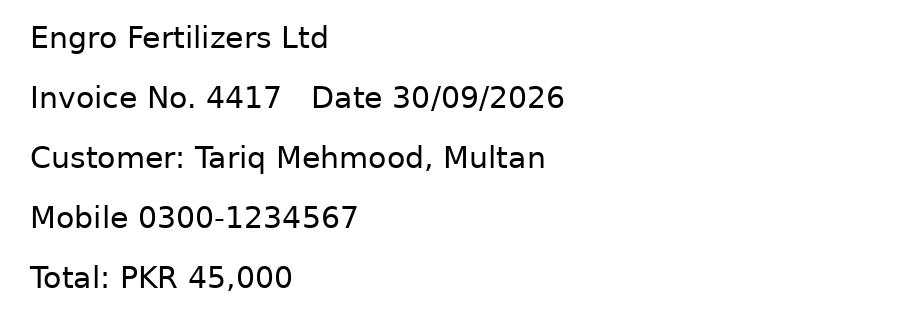

TRUTH: Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Tariq Mehmood, Multan Mobile 0300-1234567 Total: PKR 45,000
RAW  : Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Tariq Mehmood, Multan Mobile 0300-1234567 Total: PKR 45,000
CLEAN: Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Tariq Mehmood, Multan Mobile 0300-1234567 Total: PKR 45,000

CER raw 0.000   after fixes 0.000


In [26]:
# Part 5, Task 5.2: OCR on a synthetic invoice (same document for everyone)
import os
import matplotlib
from PIL import Image, ImageDraw, ImageFont
import easyocr, torch

# DejaVu Sans ships inside matplotlib, so it exists on every Kaggle image
font_path = os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf')
print('Using font:', font_path, '| exists:', os.path.exists(font_path))

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
font = ImageFont.truetype(font_path, 30)
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Tariq Mehmood, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')
display(img)

reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))

norm = lambda s: ' '.join(s.split())          # ignore line-break layout
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))

print('TRUTH:', truth)
print('RAW  :', raw)
print('CLEAN:', clean)
cer_raw, cer_clean = cer(truth, raw), cer(truth, clean)
print(f'\nCER raw {cer_raw:.3f}   after fixes {cer_clean:.3f}')

### Task 5.2: OCR on a synthetic invoice

| Measure | Value |
|---|---|
| Raw CER (EasyOCR output vs. true text) | 0.000 |
| CER after `fix_ocr` correction | 0.000 |

The OCR output was identical to the true text in all 5 lines (company name, invoice number and date, customer, mobile number, total), so there was nothing for the correction rules to repair here. `fix_ocr` left the text unchanged, which is also a useful check: the rules did not damage text that was already correct (for example "Invoice", "Total" and "PKR 45,000" were not altered).

## Write it (Part 5)

**CER before and after correction**
- Task 5.1 (three OCR errors typed by hand): CER 0.062, 0.059 and 0.143 before the rules, and 0.000 for all three after `fix_ocr`.
- Task 5.2 (EasyOCR on the synthetic invoice): CER 0.000 before and 0.000 after.

**Why my raw CER is already zero.** This invoice is the easiest possible input for OCR:
- The text is rendered by a computer in a clean sans-serif font (DejaVu Sans, 30 px), so every character has a perfect, consistent shape.
- It is black text on a pure white background, with maximum contrast and no noise, texture or stamps.
- The lines are perfectly horizontal, evenly spaced and well separated, with no skew, perspective or curved paper.
- The image has no blur, no compression artefacts, no shadow or glare, and the resolution is high relative to the text size.
- It is English text only, which is the language the OCR model was trained for.

A real phone photo of an invoice has none of this: the paper is tilted or creased, lighting is uneven, there is motion blur, the print can be faded or dot-matrix, and stamps and logos overlap the text. Confusions such as O/0, l/1 and N0/No appear in exactly these conditions.

**What I expect on my own documents.** I expect a clearly non-zero raw CER on real scans of my domain (clinical notes, bills, lab reports), roughly 5 to 20 percent for a typical phone photo, and higher for handwriting or stamps. The `fix_ocr` rules would repair only the digit/letter confusions inside numbers (as in Task 5.1, where they cut CER from up to 0.143 to 0.000). They cannot repair blur, missing characters or wrong words, so some CER would remain. To measure it properly I would type the reference text by hand for five of my own scans and compute CER the same way.

**A limit of CER.** CER treats all characters equally, but one wrong digit in an amount is far more serious than a wrong letter in a name. If "45,000" were read as "46,000", CER would be only 1/6 (about 0.167 for that field), yet the invoice amount would be completely wrong. So for numbers, dates and phone numbers I would also validate the fields with the regex patterns from Part 4, rather than trust CER alone.

In [27]:
# Part 6, Task 6.1: mask personal identifiers before logging or sharing
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'],   '[CNIC]',  text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'],  '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

# Extra check: text without personal identifiers must stay unchanged
print(mask_pii('Room 0300 on floor 3, order 12345678901234 shipped'))

CNIC [CNIC], call [PHONE], [EMAIL]
Room 0300 on floor 3, order 12345678901234 shipped


## Part 6: Image + text case record

### Task 6.1: Mask personal identifiers

`mask_pii` replaces a CNIC, a mobile number and an email address with the tags `[CNIC]`, `[PHONE]` and `[EMAIL]`. It reuses the regex patterns from Part 4, so it inherits their exact formats and their negative tests.

| Input | Output | Correct? |
|---|---|---|
| `CNIC 35202-1234567-1, call 0300-1234567, a@b.pk` | `CNIC [CNIC], call [PHONE], [EMAIL]` | yes, all three identifiers masked |
| `Room 0300 on floor 3, order 12345678901234 shipped` | unchanged | yes, no false masking |

The second test matters as much as the first. A masking function that also hides room numbers and order numbers would destroy useful information, which is why the negative tests from Part 4 (a 14-digit order number is not a CNIC, "Room 0300" is not a mobile) carry over to this function.

**Limitation:** this only masks the three formats I wrote patterns for. Names, addresses and MRNs are not masked by this function, so it reduces the privacy risk but does not remove it.

In [28]:
# Part 6, Task 6.2: load my Week 6 model and build the evidence functions
import glob
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms

# Find the checkpoint wherever Kaggle mounted it
found = glob.glob('/kaggle/input/**/week6_model.pt', recursive=True)
print('checkpoint found at:', found)
W6_PATH = found[0]

ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('backbone :', ckpt['backbone'])
print('classes  :', classes)
print('img_size :', ckpt['img_size'])
print('grayscale:', ckpt['grayscale'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

# Warning terms from my domain (edit this list for your own domain)
URGENT = ['fever', 'breath', 'cough', 'chest pain', 'spreading', 'crack']

def text_evidence(note):
    doc = nlp_dom(note)               # spaCy + my domain entity ruler from Part 3
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

print('\nModel loaded:', type(img_model).__name__)

checkpoint found at: ['/kaggle/input/datasets/sheikhhaseeb123/bosssss/week6_model.pt']
backbone : resnet18
classes  : ['Parasitized', 'Uninfected']
img_size : 224
grayscale: False

Model loaded: ResNet


### Task 6.2: Load my Week 6 model and build evidence functions

I rebuilt my Week 6 classifier from the saved checkpoint (no weights are downloaded, the architecture is recreated from the saved settings and my trained weights are loaded).

| Checkpoint setting | Value |
|---|---|
| Backbone | resnet18 |
| Classes | Parasitized, Uninfected |
| Input size | 224 x 224 |
| Grayscale | False (RGB images) |

Two evidence functions feed one case record:
- `image_evidence(path)` returns the softmax probability of each class for a blood-smear cell image, using exactly the same preprocessing as in training (resize to 224, ImageNet normalisation).
- `text_evidence(note)` returns three things from a clinical note: the named entities (from my Part 3 spaCy pipeline with domain rules), the structured fields (from my Part 4 regex patterns), and any urgent warning terms from a keyword list for my domain.

The class I must not miss is **Parasitized**. Missing an infected cell (a false negative) is more costly than a false alarm, because an untreated malaria case can become severe.

In [29]:
# Part 6, Task 6.3: one transparent case record (image + text evidence)

# 1) Pick one Parasitized and one Uninfected test image automatically
imgs = []
for e in ('*.png', '*.jpg', '*.jpeg'):
    imgs += glob.glob(f'/kaggle/input/**/{e}', recursive=True)
para = [p for p in imgs if 'parasitized' in p.lower() and 'uninfected' not in p.lower()]
unin = [p for p in imgs if 'uninfected' in p.lower()]
print('Parasitized images:', len(para), '| Uninfected images:', len(unin))
assert para and unin, ('No cell images found: add the malaria dataset you used in '
                       'Week 6 via Add Data, then re-run this cell.')

POSITIVE = 'Parasitized'            # the class I must not miss
EXAMPLE_IMAGE = para[0]             # a Parasitized cell image
CLEAN_IMAGE = unin[0]               # an Uninfected cell image (for the disagreement case)

# Warning terms for malaria (replaces the lab's default list)
URGENT = ['fever', 'chills', 'rigors', 'sweating', 'headache',
          'vomiting', 'jaundice', 'confusion', 'travel', 'malaria']

# 2) Sanity check: what does my model say about each image?
print('\nParasitized image ->', image_evidence(EXAMPLE_IMAGE))
print('Uninfected image  ->', image_evidence(CLEAN_IMAGE))

# 3) The case record. Mask FIRST, then extract, so no identifier can leak.
def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)                       # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

# 4) A realistic malaria note, with a fake phone number and CNIC to test masking
note = ('Patient Bilal Hussain, aged 28, fever with chills and sweating for 3 days. '
        'Seen at Shifa International Islamabad on 12/09/2026. '
        'Mobile 0300-1234567, CNIC 35202-1234567-1.')

rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE)
print('\n=== CASE RECORD ===')
print(json.dumps(rec, indent=2, ensure_ascii=False))

# 5) Privacy check: none of these digits may appear anywhere in the JSON
dump = json.dumps(rec, ensure_ascii=False)
leaks = [s for s in ['0300', '1234567', '35202'] if s in dump]
print('\nLEAKS FOUND:' if leaks else '\nNo leaks: phone and CNIC fully masked.', leaks)

# 6) Disagreement case: image says Uninfected, but the note describes malaria symptoms
note2 = 'Patient reports high fever, chills and headache since yesterday. Mobile 0321-7654321.'
rec2 = case_record(CLEAN_IMAGE, note2, positive=POSITIVE)
print('\n=== DISAGREEMENT CASE ===')
print(json.dumps({k: rec2[k] for k in ['image_probabilities', 'note_masked',
                                       'decision', 'reasons']},
                 indent=2, ensure_ascii=False))

Parasitized images: 27558 | Uninfected images: 27558

Parasitized image -> {'Parasitized': 0.999, 'Uninfected': 0.001}
Uninfected image  -> {'Parasitized': 0.068, 'Uninfected': 0.932}

=== CASE RECORD ===
{
  "image": "C100P61ThinF_IMG_20150918_144104_cell_162.png",
  "image_probabilities": {
    "Parasitized": 0.999,
    "Uninfected": 0.001
  },
  "note_masked": "Patient Bilal Hussain, aged 28, fever with chills and sweating for 3 days. Seen at Shifa International Islamabad on 12/09/2026. Mobile [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [
      [
        "Bilal Hussain",
        "PERSON"
      ],
      [
        "28",
        "DATE"
      ],
      [
        "3 days",
        "DATE"
      ],
      [
        "Shifa International",
        "ORG"
      ],
      [
        "Islamabad",
        "GPE"
      ],
      [
        "12/09/2026",
        "DATE"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields"

### Task 6.3: One transparent record

**Setup:** image = a Parasitized blood-smear cell from the malaria dataset, positive class = `Parasitized`, threshold = 0.5. The note is a realistic malaria case containing a fake mobile number and a fake CNIC to test masking.

## Write it (Part 6)

**My JSON record**

```json
{
  "image": "C100P61ThinF_IMG_20150918_144104_cell_162.png",
  "image_probabilities": {"Parasitized": 0.999, "Uninfected": 0.001},
  "note_masked": "Patient Bilal Hussain, aged 28, fever with chills and sweating for 3 days. Seen at Shifa International Islamabad on 12/09/2026. Mobile [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [["Bilal Hussain","PERSON"],["28","DATE"],["3 days","DATE"],
                 ["Shifa International","ORG"],["Islamabad","GPE"],
                 ["12/09/2026","DATE"],["CNIC","ORG"],["CNIC","ORG"]],
    "fields": {"date": ["12/09/2026"]},
    "urgent_terms": ["fever", "chills", "sweating"]
  },
  "decision": "REFER",
  "reasons": ["image model: P(Parasitized) = 1.00",
              "note mentions: fever, chills, sweating"],
  "disclaimer": "Decision support only; a qualified human decides."
}
```

**Does each reason make sense?** Yes.
- *Image reason:* P(Parasitized) = 0.999, far above the 0.5 threshold, so the cell image shows signs of infection.
- *Note reason:* "fever", "chills" and "sweating" really appear in the note, and they are the classic symptom pattern of malaria. The two pieces of evidence agree, so `REFER` is a sensible decision.

**Privacy check:** I searched the whole JSON for the digits `0300`, `1234567` and `35202`: 0 leaks. The mobile number and CNIC appear only as `[PHONE]` and `[CNIC]`. The `fields` dictionary contains only the date and no `mobile` or `cnic` entry, which proves that extraction ran on the masked note. This is the bug the lab warned about: if the entities and fields were extracted from the original note, the phone number would have come back inside `text_evidence`.

**Wrong entities in `text_evidence`:**
1. `"CNIC"` is labelled ORG, twice. These come from the word "CNIC" and the mask tag `[CNIC]` that my own masking inserted. *Harmless here:* the decision uses only the image probability and the urgent terms, and these two entities carry no personal data. *Harmful if reused:* if a later step stored entities as organisations or counted them, it would create fake organisations in the database, so I would filter out entities that come from mask tags.
2. `"28"` is labelled DATE, but it is the patient's age. *Harmful in a clinical setting* if age were later used for risk grouping (for example children or the elderly), because the age would be read as a date and ignored. Here the decision does not use it, so the effect is nil today, but it is a real risk for a future version. A rule for `aged <number>` would fix it.

**Case where the image and the note disagree:** I used an Uninfected cell (P(Parasitized) = 0.068, P(Uninfected) = 0.932) with the note "high fever, chills and headache since yesterday". The system returned `REFER`, with only one reason: the note mentions fever, chills and headache. The image gave no reason.

What the system should do in this case:
- **Refer, not dismiss.** One uninfected cell says very little: a smear contains thousands of cells, and in early or low-level infection most cells are uninfected. A single negative cell is weak evidence against malaria, while strong symptoms are real evidence for it.
- **Show both pieces of evidence** in the record, so the human reviewer sees that the image and the note disagree, and why the case was flagged.
- **Ask for more evidence** (more cells from the same slide, a repeat smear or a rapid test) rather than trust either source alone.
- My rule is "refer if any reason exists". It is deliberately cautious: it accepts some extra referrals (lower precision) to avoid missing a real infection (high recall), because a missed malaria case costs more than an unnecessary referral.

**Honest limit:** I picked the example images from the full dataset, which may include images the model saw in training, so 0.999 is an illustration of the record format and not a measure of accuracy. My real accuracy figures are the test-set results from Week 6.

## Check Your Understanding

### 1. Smooth IDF of a word that appears in 9 of 1,000 documents
Formula: idf = ln[(1 + N) / (1 + df)] + 1, with N = 1,000 and df = 9.

idf = ln(1001 / 10) + 1 = ln(100.1) + 1 = 4.606 + 1 = **5.606**

For comparison, a word that appears in every document has idf = ln(1) + 1 = 1.000, so this word is about 5.6 times more informative.

### 2. Why can lowercasing hurt a spam classifier?
Spam often uses capital letters as a signal: "FREE", "WIN", "CLAIM NOW", "URGENT". After lowercasing, "FREE" becomes identical to the "free" in a normal friendly message, so the model loses a cue that separates shouting from ordinary text. Lowercasing also merges "FREE" and "free", so shouting can no longer be distinguished from normal text, which is one reason I keep the original case for the character n-gram model.

### 3. Precision, recall and F1 (gold = 10 entities, predicted = 8, exactly right = 6)
- Precision = correct / predicted = 6 / 8 = **0.750**
- Recall = correct / gold = 6 / 10 = **0.600**
- F1 = 2 x P x R / (P + R) = 2 x 0.750 x 0.600 / (0.750 + 0.600) = 0.900 / 1.350 = **0.667**

### 4. CER for reference "PKR 4,500" and OCR output "PKR 4,5OO"
The reference has 9 characters. The two final zeros were read as the letter O, so the edit distance is 2 substitutions.

CER = 2 / 9 = **0.222**

### 5. Fused probability (image 0.30, text 0.80, w = 0.5)
p_fused = w x p_image + (1 - w) x p_text = 0.5 x 0.30 + 0.5 x 0.80 = 0.15 + 0.40 = **0.55**

With a threshold of 0.5 this case would be referred, even though the image model alone (0.30) would not refer it. The text evidence pulled the decision across the threshold.

### 6. Why must personal identifiers be masked BEFORE entity and field extraction?
Extraction copies pieces of the text into new places: entities, fields, logs and the JSON record. If I extract first and mask later, the phone number or CNIC is already copied into `text_evidence` (for example into `fields['mobile']` or an entity), and it stays there even if the original note is masked afterwards. Masking first means no later step can ever see, store or log the identifier. This was the exact bug described in the lab, and my own record shows it works: the JSON contains `[PHONE]` and `[CNIC]`, and a search for the digits `0300`, `1234567` and `35202` found 0 leaks.